# `Материалы кафедры ММП факультета ВМК МГУ. Введение в Эффективные Системы Глубокого Обучения.`

# `Семинар. Современные системы инференса: ONNX Runtime, vLLM, SGLang, TensorRT-LLM, llama.cpp`

## `Материалы составил: Ильясов Эрик (@erikotoz)`

### `Москва, Осенний семестр 2026`

На прошлой лекции мы разобрали, какие проблемы возникают при инференсе больших языковых моделей и как с ними справляются современные системы. Обсудили различия между prefill и decode, эффективное батчирование, управление KV-cache и способы повысить загрузку GPU при обработке большого числа запросов.

Теперь посмотрим, как эти идеи реализуются на практике. Сегодня существует множество инструментов для инференса: ONNX Runtime, vLLM, SGLang, TensorRT-LLM, llama.cpp. При этом они отличаются по архитектуре, поддерживаемому оборудованию и сценариям использования. Некоторые позволяют ускорить вычисления отдельной модели, другие ориентированы на обслуживание большого потока запросов, третьи на запуск моделей на устройствах с ограниченными ресурсами.

Цель семинара – разобраться за счёт чего современные inference-фреймворки ускоряют выполнение моделей, какие ограничения они устраняют и как оценивать эффективность этих оптимизаций на практике.



## `1. От PyTorch к системам инференса`

Мы уже умеем обучать нейросети и запускать их в PyTorch. Но когда речь заходит об эффективном инференсе, одного `model(x)` оказывается недостаточно.

Производительность зависит не только от архитектуры модели, но и от того, **как выполняются вычисления**: какие операции можно объединить, какие ядра используются и как организована работа с памятью.

Для решения этих задач существуют специализированные инструменты:

- **ONNX Runtime** — оптимизирует и исполняет вычислительные графы на различных устройствах.
- **vLLM, SGLang, TensorRT-LLM** — организуют эффективную генерацию LLM, включая батчирование запросов и управление KV-cache.
- **llama.cpp** — позволяет эффективно запускать языковые модели на различном оборудовании, в том числе локально на CPU и Apple Silicon.

### `1.1. Как оценивать эффективность?`

На предыдущей лекции мы познакомились с основными метриками инференса:

- **Latency** — время обработки одного запроса. Для LLM отдельно рассматривают TTFT (время до первого токена) и TPOT (время генерации одного выходного токена).
- **Throughput** — пропускная способность системы: запросы/с или токены/с.
- **Memory usage** — потребление памяти моделью и промежуточными вычислениями, включая KV-cache.

Эти характеристики не всегда улучшаются одновременно. Например, увеличение числа параллельных запросов может повысить throughput, но одновременно увеличить latency.

На семинаре посмотрим, **какие оптимизации используют современные inference-фреймворки и как они влияют на эти метрики**. Начнём с выполнения обычной нейросети через ONNX Runtime, а затем перейдём к специализированным системам инференса LLM.

## `2. ONNX: от PyTorch к вычислительному графу`

Начнём с **ONNX (Open Neural Network Exchange)** — формата, который позволяет представить модель в виде вычислительного графа независимо от PyTorch.

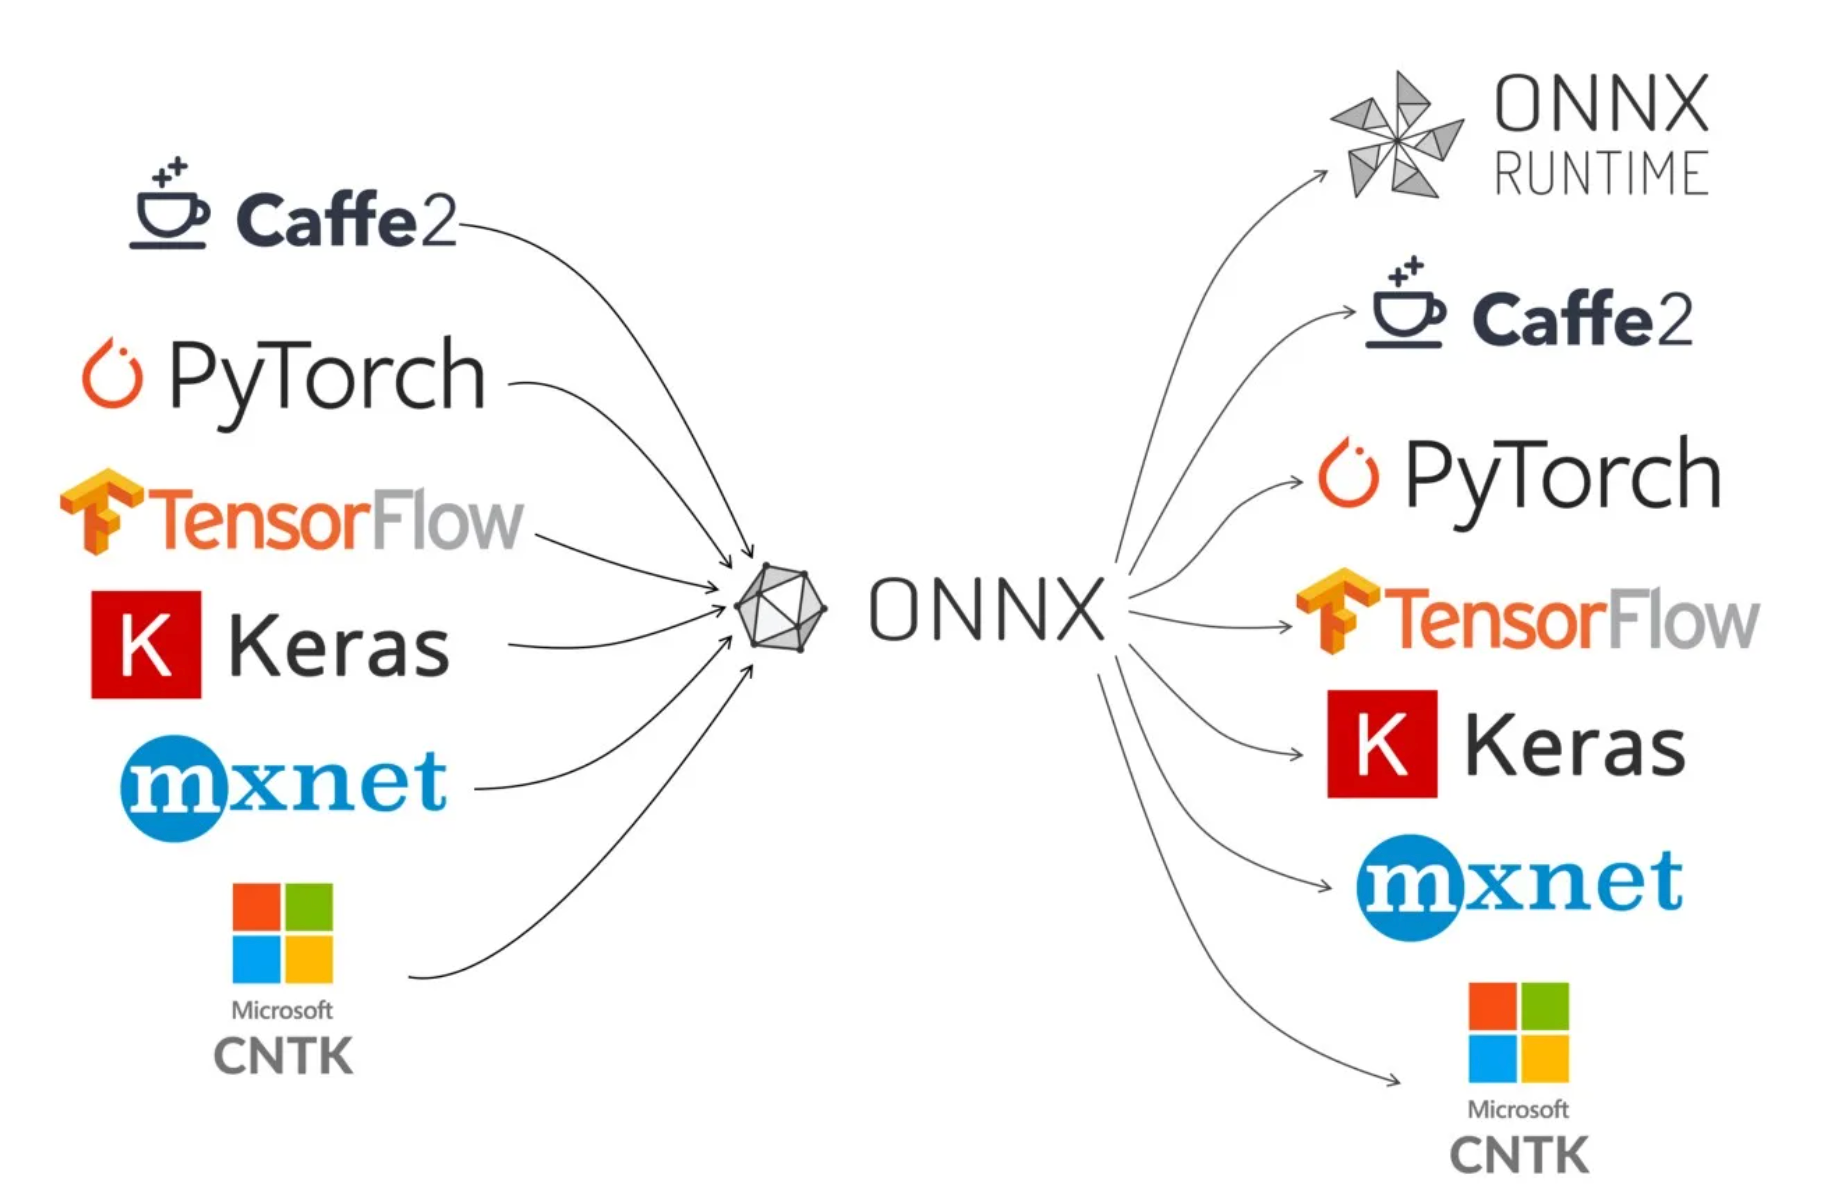

Идея состоит в том, чтобы отделить **описание вычислений от их выполнения**. Одну и ту же ONNX-модель можно запускать с помощью разных аппаратных ускорителей, не переписывая её архитектуру.

Для демонстрации возьмём простой двухслойный MLP:

$$
1024 \xrightarrow{\mathrm{Linear + ReLU}} 2048
\xrightarrow{\mathrm{Linear}} 1024.
$$

Экспортируем его в ONNX, посмотрим, из каких операций состоит граф, а затем запустим через **ONNX Runtime** и сравним производительность с PyTorch.

In [ ]:
%pip -q install "onnx>=1.16" "onnxruntime>=1.18" onnxscript "openai>=1.50" pandas matplotlib transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 5.3 MB/s eta 0:00:00


In [ ]:
%pip -q install -U vllm

In [ ]:
import os
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import onnx
import onnxruntime as ort

print("Python / platform:", platform.python_version(), platform.platform())
print("Torch:", torch.__version__, "CUDA:", torch.version.cuda)
print("CUDA device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")
print("ONNX Runtime:", ort.__version__)
print("ONNX Runtime providers:", ort.get_available_providers())

# Для CPU-сравнения фиксируем число потоков
NUM_THREADS = min(4, os.cpu_count() or 1)
torch.set_num_threads(NUM_THREADS)
print("Benchmark CPU threads:", NUM_THREADS)
torch.manual_seed(42)
np.random.seed(42)

Python / platform: 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
Torch: 2.13.0+cu130 CUDA: 13.0
CUDA device: Tesla T4
ONNX Runtime: 1.31.0
ONNX Runtime providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
Benchmark CPU threads: 2


### `2.2. Экспорт модели в ONNX`

Экспортируем модель из PyTorch в ONNX с помощью `torch.onnx.export`.

При экспорте PyTorch преобразует операции модели в ONNX-граф. При этом зададим динамический размер батча, чтобы одна экспортированная модель могла обрабатывать разное количество объектов без повторного экспорта.

In [ ]:
class TinyMLP(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(1024, 2048),
            torch.nn.ReLU(),
            torch.nn.Linear(2048, 1024),
        )

    def forward(self, x):
        return self.layers(x)

model = TinyMLP().eval().cpu().requires_grad_(False)
x_example = torch.randn(8, 1024, dtype=torch.float32)

with torch.inference_mode():
    print(model(x_example).shape)

torch.Size([8, 1024])


In [ ]:
from pathlib import Path

ONNX_PATH = "tiny_mlp.onnx"

# Размер батча оставляем динамическим: от 1 до 128 объектов.
batch_dim = torch.export.Dim("batch", min=1, max=128)

try:
    # Экспортируем PyTorch-модель в ONNX с помощью нового экспортера.
    torch.onnx.export(
        model,
        (x_example,),
        ONNX_PATH,
        input_names=["input"],
        output_names=["output"],
        dynamic_shapes=({0: batch_dim},),
        dynamo=True,
        opset_version=18,
    )
    print("Exported with dynamo=True")

except Exception as exc:
    # Если новый экспортер не сработал, используем старый API.
    print("Modern exporter failed:", type(exc).__name__, str(exc)[:300])
    print("Falling back to the legacy exporter")

    torch.onnx.export(
        model,
        (x_example,),
        ONNX_PATH,
        input_names=["input"],
        output_names=["output"],
        dynamic_axes={"input": {0: "batch"}, "output": {0: "batch"}},
        dynamo=False,
        opset_version=17,
    )

# Загружаем ONNX-граф и проверяем его корректность.
onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)

# Проверяем, не сохранил ли экспортер веса отдельно от графа.
raw_model = onnx.load(ONNX_PATH, load_external_data=False)
external_locations = set()

for initializer in raw_model.graph.initializer:
    if initializer.data_location == onnx.TensorProto.EXTERNAL:
        entries = {item.key: item.value for item in initializer.external_data}
        if entries.get("location"):
            external_locations.add(entries["location"])

# Выводим размеры графа и файлов с параметрами модели.
model_files = [Path(ONNX_PATH)] + [
    Path(ONNX_PATH).parent / f
    for f in sorted(external_locations)
]

print("ONNX model files:")
for path in model_files:
    if path.exists():
        print(f"  {path}: {path.stat().st_size / 2**20:.2f} MiB")

total_size = sum(
    p.stat().st_size for p in model_files if p.exists()
) / 2**20

print(f"Total on-disk size: {total_size:.2f} MiB")

[torch.onnx] Obtain model graph for `TinyMLP([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TinyMLP([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Exported with dynamo=True
ONNX model files:
  tiny_mlp.onnx: 0.00 MiB
  tiny_mlp.onnx.data: 16.06 MiB
Total on-disk size: 16.07 MiB


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


In [ ]:
from collections import Counter

graph = onnx_model.graph
print("Inputs:", [(v.name, [d.dim_param or d.dim_value for d in v.type.tensor_type.shape.dim]) for v in graph.input])
print("Outputs:", [v.name for v in graph.output])
print("Operators:", Counter(node.op_type for node in graph.node))
print("Number of initializers:", len(graph.initializer))

Inputs: [('input', ['batch', 1024])]
Outputs: ['output']
Operators: Counter({'Gemm': 2, 'Relu': 1})
Number of initializers: 4


Граф содержит две операции Gemm (матричное умножение с прибавлением смещения) и одну Relu. Четыре initializer – это веса и смещения двух линейных слоёв, занимающие около 16 MiB.

Таким образом, мы сохранили архитектуру и параметры модели в формате ONNX, независимо от PyTorch.

### `2.3. ONNX Runtime: оптимизируем и исполняем граф`

Теперь запустим экспортированную модель через **ONNX Runtime**.

При создании `InferenceSession` ONNX Runtime загружает вычислительный граф, применяет доступные оптимизации и подготавливает операции к выполнению на выбранном устройстве.

Для начала проверим, что PyTorch и ONNX Runtime выдают одинаковые результаты с учётом погрешности вычислений с плавающей точкой.

In [ ]:
def make_ort_session(level, optimized_path=None, providers=None):
    options = ort.SessionOptions()

    # Уровень оптимизации вычислительного графа
    options.graph_optimization_level = level

    # Настройки параллелизма CPU
    options.intra_op_num_threads = NUM_THREADS
    options.inter_op_num_threads = 1

    # При необходимости сохраняем оптимизированный граф
    if optimized_path:
        options.optimized_model_filepath = optimized_path

    return ort.InferenceSession(
        ONNX_PATH,
        sess_options=options,
        providers=providers or ["CPUExecutionProvider"],
    )


# Создаём сессию с включёнными оптимизациями
sess_basic = make_ort_session(
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

# Выполняем одну модель на одинаковых входных данных
x_np = x_example.numpy()

with torch.inference_mode():
    y_pt = model(x_example).numpy()

y_ort = sess_basic.run(None, {"input": x_np})[0]

# Проверяем численную близость результатов.
np.testing.assert_allclose(y_pt, y_ort, rtol=1e-4, atol=1e-5)

print("Max abs diff:", np.max(np.abs(y_pt - y_ort)))
print("ORT outputs shape:", y_ort.shape)

Max abs diff: 3.6507845e-07
ORT outputs shape: (8, 1024)


ONNX Runtime может преобразовывать исходный граф, например объединять несколько последовательных операций в одну (*operator fusion*).

Создадим две сессии – с отключёнными и включёнными оптимизациями – и сравним получившиеся графы.

In [ ]:
# Сессия без оптимизаций графа
sess_off = make_ort_session(
    ort.GraphOptimizationLevel.ORT_DISABLE_ALL
)

# Сессия с максимальным уровнем оптимизаций
# Сохраняем преобразованный граф для анализа
sess_all = make_ort_session(
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL,
    optimized_path="tiny_mlp_optimized.onnx",
)

print("Providers:", sess_all.get_providers())
print(
    "Saved optimized graph:",
    Path("tiny_mlp_optimized.onnx").exists()
)

# Сравниваем наборы операторов до и после оптимизации
try:
    optimized_graph = onnx.load("tiny_mlp_optimized.onnx").graph

    print(
        "Before:",
        Counter(n.op_type for n in onnx_model.graph.node)
    )
    print(
        "After:",
        Counter(n.op_type for n in optimized_graph.node)
    )

except Exception as exc:
    print(
        "Cannot inspect optimized graph:",
        type(exc).__name__
    )

Providers: ['CPUExecutionProvider']
Saved optimized graph: True
Before: Counter({'Gemm': 2, 'Relu': 1})
After: Counter({'FusedGemm': 1, 'Gemm': 1})


После оптимизации ONNX Runtime объединил первую линейную операцию с активацией в FusedGemm.

Такое объединение позволяет сократить число отдельных операций и избежать лишней работы с промежуточными данными, что *потенциально* ускоряет инференс.

### `2.4. Сравнение производительности PyTorch и ONNX Runtime`

Мы увидели, как ONNX Runtime оптимизирует вычислительный граф. Теперь проверим, насколько это влияет на скорость инференса.

Сравним три варианта: **PyTorch**, **ONNX Runtime без оптимизаций** и **ONNX Runtime с оптимизациями**.

Для каждого измерим время выполнения модели при разных размерах батча. Используем одинаковые входные данные, число CPU-потоков и предварительный прогрев, чтобы сравнение было корректным.

In [ ]:

from torch.utils.benchmark import Timer
import random

BENCH_REPEATS = 5
BENCH_MIN_RUN_TIME = 0.3
BATCHES = [1, 4, 16, 64]

# Заранее создаём входы для разных размеров батча.
bench_inputs = {
    b: torch.randn(b, 1024, dtype=torch.float32)
    for b in BATCHES
}

# Проверяем совпадение результатов PyTorch и ORT.
for b, xb in bench_inputs.items():
    with torch.inference_mode():
        ref = model(xb).numpy()

    np.testing.assert_allclose(
        ref,
        sess_all.run(None, {"input": xb.numpy()})[0],
        rtol=1e-4,
        atol=1e-5,
    )

# Подготавливаем входы ONNX Runtime вне измеряемого участка.
bench_payloads = {
    b: {"input": xb.numpy()}
    for b, xb in bench_inputs.items()
}

# Создаём таймер для каждой конфигурации.
measurements = {
    (b, runtime): Timer(
        stmt=(
            "model(x)"
            if runtime == "PyTorch"
            else "session.run(None, payload)"
        ),
        globals=(
            {"model": model, "x": bench_inputs[b]}
            if runtime == "PyTorch"
            else {
                "session": sess_off if runtime == "ORT no opt" else sess_all,
                "payload": bench_payloads[b],
            }
        ),
        num_threads=NUM_THREADS,
    )
    for b in BATCHES
    for runtime in ("PyTorch", "ORT no opt", "ORT all")
}

# Прогрев перед измерениями.
with torch.inference_mode():
    for timer in measurements.values():
        timer.timeit(10)

# Повторяем измерения, меняя порядок конфигураций.
raw_rows = []
keys = list(measurements)
rng = random.Random(42)

with torch.inference_mode():
    for repeat in range(BENCH_REPEATS):
        rng.shuffle(keys)

        for batch, runtime in keys:
            sample_ms = 1000 * measurements[
                (batch, runtime)
            ].blocked_autorange(
                min_run_time=BENCH_MIN_RUN_TIME
            ).median

            raw_rows.append({
                "repeat": repeat,
                "batch": batch,
                "runtime": runtime,
                "latency_ms": sample_ms,
            })

# Агрегируем результаты: медиана и межквартильный размах.
raw_onnx_bench = pd.DataFrame(raw_rows)

median_table = (
    raw_onnx_bench
    .groupby(["batch", "runtime"])["latency_ms"]
    .median()
    .unstack()
)

spread_table = (
    raw_onnx_bench
    .groupby(["batch", "runtime"])["latency_ms"]
    .agg(lambda a: np.percentile(a, 75) - np.percentile(a, 25))
    .unstack()
)

onnx_bench = median_table.reset_index().rename(columns={
    "PyTorch": "PyTorch, ms",
    "ORT no opt": "ORT no opt, ms",
    "ORT all": "ORT all, ms",
})

print("Median latency (ms):")
display(onnx_bench.round(3))

print("IQR (ms):")
display(spread_table.round(3))

raw_onnx_bench.to_csv("onnx_benchmark_raw.csv", index=False)

Median latency (ms):


runtime,batch,"ORT all, ms","ORT no opt, ms","PyTorch, ms"
0,1,1.461,2.005,2.111
1,4,2.361,1.640,3.807
2,16,4.020,3.220,9.701
3,64,10.946,9.991,17.739


IQR: 75th - 25th percentile (ms), smaller = more stable:


runtime,ORT all,ORT no opt,PyTorch
batch,,,
1,0.519,1.542,0.160
4,0.856,0.050,0.314
16,2.489,0.166,4.687
64,2.907,3.506,14.149


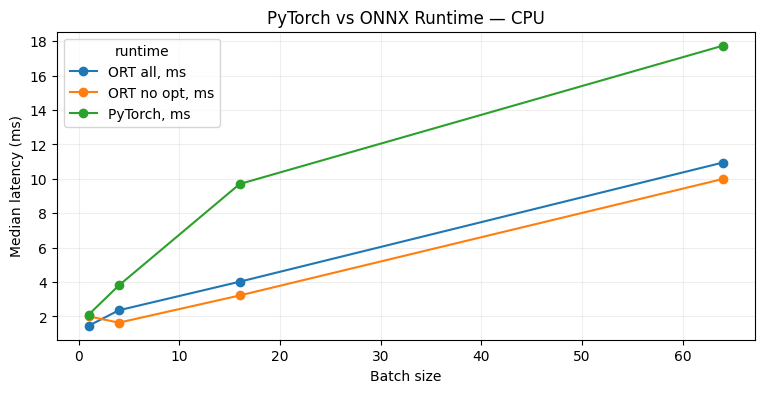

In [ ]:
ax = onnx_bench.set_index("batch").plot(marker="o", figsize=(9, 4))
ax.set(xlabel="Batch size", ylabel="Median latency (ms)", title="PyTorch vs ONNX Runtime — CPU")
ax.grid(alpha=0.2)
plt.show()

In [ ]:
onnx_bench["ORT speedup vs PyTorch"] = onnx_bench["PyTorch, ms"] / onnx_bench["ORT all, ms"]
display(onnx_bench[["batch", "ORT speedup vs PyTorch"]].round(2))

runtime,batch,ORT speedup vs PyTorch
0,1,1.44
1,4,1.61
2,16,2.41
3,64,1.62


На нашем MLP ONNX Runtime оказался быстрее PyTorch, причём величина ускорения зависит от размера батча. Оптимизация графа и выбор среды исполнения могут заметно ускорить инференс даже без изменения архитектуры и весов модели. При этом выигрыш зависит от модели, оборудования и характера нагрузки.




**Вопрос:** Можно ли ожидать аналогичного ускорения от ONNX Runtime при генерации токенов в больших языковых моделях?

<details>
<summary><b>Ответ</b></summary>

Необязательно. В нашем эксперименте основная нагрузка приходилась на матричные умножения, которые эффективно выполняются при достаточно больших батчах.

В LLM на этапе **decode** на каждом шаге генерируется один токен для каждой последовательности. При небольшом батче вычисления часто ограничены **пропускной способностью памяти (memory bandwidth)**, а не производительностью GPU.

Поэтому ускорения отдельных операций недостаточно. Для эффективной генерации особенно важны **батчирование запросов, управление KV-cache и организация работы с памятью** — именно на этом специализируются LLM inference engines.

</details>


## `3. Execution Providers: запуск ONNX на разных устройствах`

Как ONNX Runtime определяет, где выполнять операции модели — на CPU, GPU или NPU?

Для этого используются **Execution Providers (EP)** — компоненты, которые связывают ONNX Runtime с конкретными аппаратными ускорителями и вычислительными библиотеками, например CUDA, TensorRT или CoreML.

При запуске модели ONNX Runtime определяет, какие части графа поддерживаются доступными Execution Providers, и распределяет вычисления между ними с учётом приоритетов.

Если ускоритель не поддерживает некоторые операции, их можно выполнить на CPU. Однако **передача данных между устройствами тоже требует времени**, поэтому использование GPU или NPU не всегда гарантирует ускорение.

Посмотрим, какие Execution Providers доступны в нашем окружении и как выбрать их при запуске модели.

![Схема исполнения ONNX Runtime: граф, partitioner, Execution Providers и оборудование](https://onnxruntime.ai/images/ONNX_Runtime_EP3.png)

*Схема исполнения ONNX Runtime: граф, partitioner, Execution Providers и оборудование — [источник](https://onnxruntime.ai/docs/execution-providers/).*

In [ ]:
providers_available = ort.get_available_providers()
providers_priority = [p for p in ["CUDAExecutionProvider", "CoreMLExecutionProvider", "CPUExecutionProvider"] if p in providers_available]
print("Available:", providers_available)
print("Preferred order:", providers_priority)

sess_priority = make_ort_session(
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL,
    providers=providers_priority,
)
print("Registered providers:", sess_priority.get_providers())
print("Output shape:", sess_priority.run(None, {"input": x_np})[0].shape)

Available: ['AzureExecutionProvider', 'CPUExecutionProvider']
Preferred order: ['CPUExecutionProvider']
Registered providers: ['CPUExecutionProvider']
Output shape: (8, 1024)


В нашем Colab доступен только **CPU Execution Provider**. Чтобы запускать ONNX-модели на NVIDIA GPU, необходимо установить `onnxruntime-gpu` с совместимыми версиями CUDA и cuDNN.

Проверить фактическое распределение вычислений можно с помощью **профилирования ONNX Runtime**, которое показывает время выполнения отдельных операций и используемые Execution Providers.

Таким образом, ONNX позволяет переносить модель между различными платформами, но **не гарантирует одинаковую производительность на разных устройствах**.

Подробнее: [ONNX Runtime — High Level Design](https://onnxruntime.ai/docs/reference/high-level-design.html).

## `4. От ONNX Runtime к LLM inference engines`

ONNX Runtime позволяет эффективно выполнять вычислительный граф модели. Но для языковых моделей этого недостаточно: генерация текста состоит из множества последовательных проходов, а каждый запрос имеет собственный контекст и KV-cache.

На предыдущей лекции мы разобрали, как **continuous batching** позволяет динамически объединять запросы на каждом шаге генерации, а **PagedAttention** — эффективно управлять памятью под KV-cache.

Для реализации этих механизмов существуют специализированные **LLM inference engines** — vLLM, SGLang и TensorRT-LLM. Они не только выполняют вычисления модели, но и управляют запросами, планируют генерацию и распределяют память.

![Временная линия prefill/decode при конкурентных запросах (TNG / Hugging Face)](https://cdn-uploads.huggingface.co/production/uploads/65263bfb3177c2a794997821/Vvy8THpBXeSvu8CN8z66t.png)

*Временная линия prefill/decode при конкурентных запросах (TNG / Hugging Face) — [источник](https://huggingface.co/blog/tngtech/llm-performance-prefill-decode-concurrent-requests).*

### `4.1. PagedAttention: эффективное хранение KV-cache`

При генерации каждому запросу необходим собственный KV-cache, размер которого увеличивается с длиной последовательности. Если заранее выделять память под максимальную длину контекста, значительная часть VRAM может оставаться неиспользованной.

**PagedAttention** решает эту проблему, разбивая KV-cache на блоки фиксированного размера. Логические блоки одной последовательности могут размещаться в разных участках физической памяти, а соответствие между ними хранится в *block table*.

Это позволяет выделять память по мере генерации, уменьшать фрагментацию и переиспользовать KV-блоки между запросами.

Размер KV-cache для одной последовательности можно оценить как:

$$
M_{\text{KV}} =
2 \cdot L \cdot T \cdot H_{\text{KV}} \cdot D \cdot s,
$$

где $L$ — число слоёв с KV-cache, $T$ — число токенов, $H_{\text{KV}}$ — число KV-heads, $D$ — размерность головы, $s$ — число байт на элемент.

Таким образом, **PagedAttention оптимизирует использование памяти**, а continuous batching — планирование запросов. Вместе эти механизмы позволяют эффективнее обслуживать множество последовательностей одновременно.

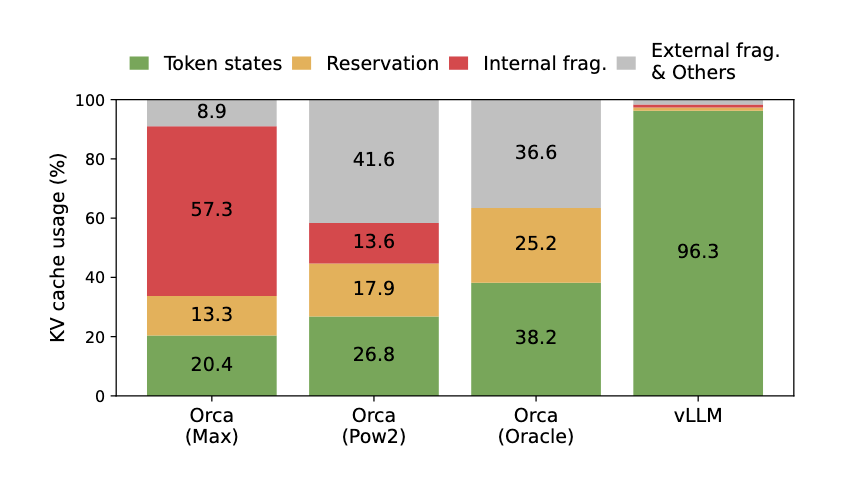

## `5. vLLM: запускаем inference-сервер`

**vLLM** — один из наиболее популярных фреймворков для высокопроизводительного инференса больших языковых моделей. Он объединяет оптимизированные вычисления, управление KV-cache и планирование запросов в единую систему.

В основе vLLM лежат несколько компонентов:

- **Scheduler** — определяет, какие запросы и сколько токенов обрабатывать на следующем шаге.
- **KV-cache manager** — управляет выделением и освобождением памяти под KV-cache.
- **Model runner** — выполняет вычисления модели на GPU.
- **API server** — принимает запросы и возвращает сгенерированные токены.

На каждом шаге движок планирует вычисления, запускает модель и обрабатывает полученные токены. Подробнее эта архитектура описана в статье [Inside vLLM](https://vllm.ai/blog/2025-09-05-anatomy-of-vllm).

Запустим vLLM как отдельный сервер и посмотрим, как он обрабатывает запросы через OpenAI-совместимый API.

![Архитектура LLM engine в официальной документации vLLM (концептуальная схема)](https://docs.vllm.ai/en/v0.15.1/assets/design/arch_overview/llm_engine.excalidraw.png)

*Архитектура LLM engine в официальной документации vLLM (концептуальная схема) — [источник](https://docs.vllm.ai/en/v0.15.1/design/arch_overview/).*

### `5.1. Запуск vLLM на GPU`

Запустим **Qwen2.5-0.5B-Instruct** на NVIDIA T4 через vLLM. Небольшая модель позволит исследовать производительность inference-сервера при разном количестве одновременных запросов.

При запуске зададим несколько параметров:

- `max_model_len=2048` — максимальная длина последовательности в токенах.
- `max_num_seqs=32` — ограничение на число одновременно обрабатываемых последовательностей.
- `gpu_memory_utilization=0.75` — доля доступной GPU-памяти, которую vLLM может использовать для своего экземпляра движка.
- `enforce_eager=True` — выполнение без CUDA Graphs, что упрощает запуск, но может снижать производительность.

Сначала запустим сервер **без prefix caching**, чтобы исследовать влияние конкурентности на throughput и latency. Позже отдельно измерим эффект кеширования.

In [ ]:
import torch

# Проверяем доступность CUDA и определяем GPU, на котором будем запускать vLLM.
# Модель видеокарты и объём VRAM важны для интерпретации результатов benchmark.
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    # Общий объём видеопамяти, выраженный в GiB.
    total_gib = torch.cuda.get_device_properties(0).total_memory / 2**30
    print(f"GPU memory: {total_gib:.1f} GiB")
else:
    print("NVIDIA GPU не обнаружен. Для запуска vLLM необходим CUDA runtime.")

CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GiB


In [ ]:
import importlib.util
import subprocess
import sys

# Проверяем, что vLLM установлен в том же Python-окружении,
# которое использует текущий Jupyter kernel.
print("Python:", sys.executable)

if importlib.util.find_spec("vllm") is None:
    raise RuntimeError("vLLM не установлен в текущем окружении")

# Запускаем CLI через sys.executable, чтобы не зависеть от PATH
# и случайно не использовать другую установку vLLM.
check = subprocess.run(
    [sys.executable, "-m", "vllm.entrypoints.cli.main", "--version"],
    capture_output=True,
    text=True,
    timeout=90,
)

# Проверяем, что CLI действительно запускается, и выводим версию.
if check.returncode != 0:
    raise RuntimeError(
        f"Ошибка запуска vLLM CLI:\n{check.stderr[-2000:]}"
    )

print("vLLM version:", check.stdout.strip())

Kernel Python: /usr/bin/python3
vLLM installed: True
CLI exit code: 0
0.32.0



In [ ]:
import json
import os
import signal
import subprocess
import time
import urllib.request
import sys
import importlib.util
from pathlib import Path

# Конфигурация inference-сервера.
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
PORT = 8765
BASE_URL = f"http://127.0.0.1:{PORT}"

# Сохраняем лог, PID и конфигурацию между запусками ячеек.
LOG_PATH = Path("vllm_server.log")
PID_PATH = Path("vllm_sem.pid")
STATE_PATH = Path("vllm_sem_state.json")

server_process = None


def server_ready():
    """Проверяем готовность сервера через HTTP health endpoint."""
    try:
        with urllib.request.urlopen(f"{BASE_URL}/health", timeout=2) as resp:
            return resp.status == 200
    except Exception:
        return False


def _owned_pid():
    """Находим процесс vLLM, запущенный из нашего ноутбука."""
    try:
        pid = int(PID_PATH.read_text().strip())

        # Проверяем командную строку процесса, чтобы не завершить чужой процесс.
        cmd = (
            Path(f"/proc/{pid}/cmdline")
            .read_bytes()
            .replace(b"\x00", b" ")
            .decode(errors="replace")
        )

        if "vllm" in cmd.lower() and "serve" in cmd.lower():
            return pid

    except (ValueError, FileNotFoundError, PermissionError, ProcessLookupError):
        pass

    return None


def stop_vllm_server():
    """Останавливаем сервер перед изменением его конфигурации."""
    pid = _owned_pid()

    if pid is None:
        if server_ready():
            raise RuntimeError("Порт занят другим сервером")

        PID_PATH.unlink(missing_ok=True)
        STATE_PATH.unlink(missing_ok=True)
        return

    # Сервер запускается в отдельной process group.
    # SIGTERM позволяет корректно завершить дочерние процессы vLLM.
    try:
        os.killpg(os.getpgid(pid), signal.SIGTERM)
    except ProcessLookupError:
        pass

    # Ожидаем освобождения порта.
    for _ in range(40):
        if not server_ready():
            break
        time.sleep(0.5)
    else:
        # Принудительное завершение, если сервер не остановился за 20 секунд.
        try:
            os.killpg(os.getpgid(pid), signal.SIGKILL)
        except ProcessLookupError:
            pass
        time.sleep(1)

    if server_ready():
        raise RuntimeError("Не удалось остановить сервер")

    PID_PATH.unlink(missing_ok=True)
    STATE_PATH.unlink(missing_ok=True)


def _prefix_flag(enabled):
    """Определяем поддерживаемый CLI-флаг prefix caching."""

    import re

    cli = [sys.executable, "-m", "vllm.entrypoints.cli.main"]

    # Синтаксис флагов отличается между версиями vLLM.
    candidates = (
        ("--enable-prefix-caching",)
        if enabled
        else ("--no-enable-prefix-caching", "--disable-prefix-caching")
    )

    # В новых версиях обычный --help не показывает все аргументы.
    for help_option in ("--help=prefix-caching", "--help=all", "--help"):
        try:
            result = subprocess.run(
                [*cli, "serve", help_option],
                capture_output=True,
                text=True,
                timeout=90,
            )
        except (OSError, subprocess.TimeoutExpired):
            continue

        if result.returncode != 0:
            continue

        help_text = result.stdout + "\n" + result.stderr

        for flag in candidates:
            if re.search(
                r"(?<![\w-])" + re.escape(flag) + r"(?![\w-])",
                help_text,
            ):
                return flag

    raise RuntimeError(
        "Не удалось определить флаг prefix caching для установленной версии vLLM"
    )


def start_vllm_server(enable_prefix_caching=False):
    """Запускаем vLLM с заданной конфигурацией кеширования."""

    global server_process

    if not torch.cuda.is_available():
        raise RuntimeError("Для запуска vLLM необходим NVIDIA GPU")

    requested_state = {
        "model": MODEL_ID,
        "prefix_cache": bool(enable_prefix_caching),
    }

    owned_pid = _owned_pid()

    # Если сервер уже работает с нужной конфигурацией,
    # повторно загружать модель в GPU-память не требуется.
    if server_ready():
        if owned_pid is None:
            raise RuntimeError(f"Порт {PORT} занят другим процессом")

        actual_state = (
            json.loads(STATE_PATH.read_text())
            if STATE_PATH.exists()
            else {}
        )

        if actual_state == requested_state:
            print("Сервер уже запущен с нужной конфигурацией")
            return

        # Изменение prefix caching требует перезапуска engine.
        stop_vllm_server()

    elif owned_pid is not None:
        stop_vllm_server()

    if importlib.util.find_spec("vllm") is None:
        raise RuntimeError("vLLM не установлен в текущем Python-окружении")

    # Запускаем сервер через Python текущего Jupyter kernel.
    cmd = [
        sys.executable,
        "-m", "vllm.entrypoints.cli.main",
        "serve", MODEL_ID,
        "--host", "127.0.0.1",
        "--port", str(PORT),

        # FP16 поддерживается Tesla T4, в отличие от BF16.
        "--dtype", "float16",

        # Максимальная длина входной и сгенерированной последовательности.
        "--max-model-len", "2048",

        # Доля VRAM, доступная для экземпляра vLLM.
        "--gpu-memory-utilization", "0.75",

        # Верхняя граница числа одновременно обрабатываемых последовательностей.
        "--max-num-seqs", "32",

        # Используем eager execution без CUDA Graphs.
        "--enforce-eager",

        # Управляем prefix caching независимо от остальных оптимизаций.
        _prefix_flag(enable_prefix_caching),
    ]

    print("Запуск vLLM:", " ".join(cmd))

    # Сервер работает в фоновом процессе, поэтому Jupyter
    # сможет отправлять ему HTTP-запросы из следующих ячеек.
    with LOG_PATH.open("w", encoding="utf8") as log_file:
        server_process = subprocess.Popen(
            cmd,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            start_new_session=True,
        )

    PID_PATH.write_text(str(server_process.pid))
    STATE_PATH.write_text(json.dumps(requested_state))

    # Загрузка модели и инициализация KV-cache могут занимать
    # десятки секунд, особенно при первом запуске в Colab.
    for elapsed in range(0, 361, 3):

        if server_ready():
            print(f"vLLM готов (~{elapsed} с)")
            print(f"Prefix caching: {enable_prefix_caching}")
            return

        # Если процесс завершился, выводим лог для диагностики.
        if server_process.poll() is not None:
            print("\n".join(
                LOG_PATH.read_text(errors="replace").splitlines()[-40:]
            ))
            raise RuntimeError("Ошибка запуска vLLM")

        time.sleep(3)

    print("\n".join(LOG_PATH.read_text(errors="replace").splitlines()[-40:]))
    raise TimeoutError("vLLM не запустился за 6 минут")


# Первый эксперимент: изучаем влияние конкурентности без prefix caching.
# Позже отдельно сравним сервер с включённым и отключённым кешированием.
start_vllm_server(enable_prefix_caching=False)

print("Server ready:", server_ready())

Prefix caching: OFF -> --no-enable-prefix-caching
Launching: /usr/bin/python3 -m vllm.entrypoints.cli.main serve Qwen/Qwen2.5-0.5B-Instruct --host 127.0.0.1 --port 8765 --dtype float16 --max-model-len 2048 --gpu-memory-utilization 0.75 --max-num-seqs 32 --enforce-eager --no-enable-prefix-caching
Waiting for vLLM... 30s
Waiting for vLLM... 60s
vLLM is ready after ~90s; prefix cache = False
Server ready: True


В нашем эксперименте использовались **vLLM 0.32.0** и **NVIDIA Tesla T4 (14.6 GiB)**.

### `5.2. OpenAI-compatible API`

vLLM предоставляет **OpenAI-совместимый API**, поэтому к нему можно обращаться с помощью стандартного Python-клиента `openai`.

Приложению достаточно передать сообщения и параметры генерации. Сервер самостоятельно применяет шаблон диалога (*chat template*), токенизирует входной текст и организует генерацию.

Посмотрим, как отправить запрос к нашему серверу и получить ответ в потоковом режиме.

In [ ]:
from openai import OpenAI, AsyncOpenAI

# Запускаем сервер без prefix caching для последующих экспериментов.
start_vllm_server(enable_prefix_caching=False)

# Подключаемся к локальному vLLM через OpenAI-совместимый API.
client = OpenAI(
    base_url=f"{BASE_URL}/v1",
    api_key="EMPTY",
    timeout=120.0,
)

# Получаем идентификатор модели, загруженной на сервере.
SERVED_MODEL = client.models.list().data[0].id
print("Model:", SERVED_MODEL)

# Отправляем запрос в формате chat completions.
# vLLM применяет chat template модели и выполняет генерацию на GPU.
answer = client.chat.completions.create(
    model=SERVED_MODEL,
    messages=[
        {
            "role": "user",
            "content": (
                "In one sentence, distinguish prefill from decode "
                "in autoregressive language model serving."
            ),
        }
    ],
    temperature=0.0,
    max_tokens=32,
)

# Выводим результат генерации и статистику использованных токенов.
print("Generated text:", answer.choices[0].message.content)
print("Finish reason:", answer.choices[0].finish_reason)

if answer.usage:
    print("Prompt tokens:", answer.usage.prompt_tokens)
    print("Completion tokens:", answer.usage.completion_tokens)

Используем уже запущенный сервер с правильной конфигурацией
Server models: ['Qwen/Qwen2.5-0.5B-Instruct']
Generated text: Prefill refers to the process of generating text based on previously seen data, while decode involves understanding and producing new text that is not directly related to the input sequence
Finish reason: length
Prompt tokens: 46
Completion tokens: 32


### `5.3. Как конкурентность влияет на производительность vLLM`

Теперь посмотрим, как vLLM справляется с одновременными запросами.

Отправим **48 запросов** к одному серверу, постепенно увеличивая число параллельных клиентов: `1, 2, 4, 8, 16, 32`. Модель и параметры генерации остаются неизменными, prefix caching отключён.

Будем измерять:

- **TTFT (Time to First Token)** — время от отправки запроса до первого сгенерированного токена.
- **E2E latency** — полное время обработки запроса.
- **Throughput** — суммарное количество сгенерированных токенов в секунду.

Для измерений используем **streaming API**, который позволяет фиксировать время появления первого токена.

Ожидаем, что увеличение конкурентности позволит эффективнее загружать GPU и повысить throughput. Однако при большом количестве запросов начнёт расти время ожидания вычислений, а вместе с ним и latency.

Наша цель — увидеть, **при какой нагрузке дальнейшее увеличение конкурентности перестаёт давать существенный прирост throughput, но заметно увеличивает задержки**.

In [ ]:
import asyncio
import time
from transformers import AutoTokenizer
from openai import AsyncOpenAI

# Используем токенизатор той же модели, что загружена в vLLM.
# Он понадобится для подсчёта сгенерированных токенов.
llm_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Асинхронный клиент позволяет отправлять несколько HTTP-запросов одновременно.
async_client = AsyncOpenAI(
    base_url=f"{BASE_URL}/v1",
    api_key="EMPTY",
    timeout=120.0,
    max_retries=0,
)

# Формируем 48 запросов на разные темы ML.
# Используем одинаковую структуру промптов и параметры генерации,
# чтобы сравнивать производительность при разной конкурентности.
TOPICS = [
    "Gradient descent and learning rate", "Bias variance tradeoff",
    "Batch normalization", "Self attention in Transformers",
    "Stochastic gradient descent", "Overfitting and regularization",
    "Cross entropy loss", "Convolution in image models",
    "Dropout in neural networks", "Principal component analysis",
    "Adam optimizer", "Embeddings for text",
    "Vanishing gradients in RNNs", "Diffusion generative models",
    "Precision and recall", "Autoregressive token generation",
    "Quantization for inference", "Knowledge distillation",
    "The Kullback Leibler divergence", "Mixture of experts routing",
    "Contrastive learning", "The softmax function",
    "Memory bandwidth on GPUs", "KV caching in LLMs",
]

PROMPTS = [
    f"Case {i}: {TOPICS[i % len(TOPICS)]}. "
    "Define it, give an application, and name a limitation."
    for i in range(48)
]


async def request_once(prompt, max_tokens=48):
    """Отправляет один запрос и измеряет задержки генерации."""

    # Начинаем измерение непосредственно перед отправкой HTTP-запроса.
    # Ожидание свободного слота клиента сюда не входит.
    started = time.perf_counter()
    first_token = None
    pieces = []

    # Streaming позволяет измерить TTFT, не дожидаясь полного ответа.
    stream = await async_client.chat.completions.create(
        model=SERVED_MODEL,
        messages=[{"role": "user", "content": prompt}],
        temperature=0.0,
        max_tokens=max_tokens,
        stream=True,
    )

    async for event in stream:
        for choice in event.choices:
            delta = choice.delta
            chunk = (delta.content or "") if delta is not None else ""

            if chunk:
                # Время до первого непустого текстового фрагмента.
                # Это клиентская оценка TTFT, включающая сетевые накладные расходы.
                if first_token is None:
                    first_token = time.perf_counter() - started

                pieces.append(chunk)

    output = "".join(pieces)

    return {
        "ttft_s": first_token if first_token is not None else float("nan"),
        "e2e_s": time.perf_counter() - started,

        # Оцениваем число выходных токенов по декодированному тексту.
        # Это приближение: специальная токенизация и служебные токены
        # могут отличаться от фактического счётчика сервера.
        "output_tokens": len(
            llm_tokenizer.encode(output, add_special_tokens=False)
        ),
        "response": output,
    }


async def run_load_test(prompts, concurrency, max_tokens=48):
    """Измеряет обработку набора запросов при заданной конкурентности."""

    # Semaphore ограничивает количество одновременных запросов
    # на стороне клиента, а не число последовательностей внутри vLLM.
    sem = asyncio.Semaphore(concurrency)

    async def limited_request(prompt):
        queued_at = time.perf_counter()

        async with sem:
            # Время ожидания клиентского слота.
            # Не следует путать его с очередью scheduler внутри vLLM.
            client_queue_s = time.perf_counter() - queued_at

            result = await request_once(
                prompt,
                max_tokens=max_tokens,
            )

            return {
                "client_queue_s": client_queue_s,
                **result,
            }

    # Wall time включает обработку всех запросов и ожидание клиентских слотов.
    # Именно на него будем делить общее число сгенерированных токенов.
    start = time.perf_counter()

    results = await asyncio.gather(
        *(limited_request(p) for p in prompts)
    )

    wall_time = time.perf_counter() - start

    return results, wall_time

In [ ]:
# Восстанавливаем конфигурацию сервера: исследуем конкурентность
# отдельно от влияния prefix caching.
start_vllm_server(enable_prefix_caching=False)

state = json.loads(STATE_PATH.read_text())
assert server_ready() and state["prefix_cache"] is False

# Создаём новый HTTP-клиент после возможного перезапуска сервера.
await async_client.close()

async_client = AsyncOpenAI(
    base_url=f"{BASE_URL}/v1",
    api_key="EMPTY",
    timeout=120.0,
    max_retries=0,
)

# Прогреваем сервер, чтобы начальная инициализация
# не влияла на результаты измерений.
_ = await request_once(
    "Describe attention mechanism in machine learning.",
    max_tokens=32,
)

# Изменяем только конкурентность, сохраняя один набор из 48 запросов.
BENCH_LEVELS = [1, 2, 4, 8, 16, 32]
LOAD_REPEATS = 1

load_rows = []

for repeat in range(LOAD_REPEATS):
    for level in BENCH_LEVELS:
        results, wall_s = await run_load_test(
            PROMPTS,
            concurrency=level,
            max_tokens=48,
        )

        # Собираем задержки отдельных запросов.
        ttft = [r["ttft_s"] for r in results if np.isfinite(r["ttft_s"])]
        e2e = [r["e2e_s"] for r in results]

        # Клиентская очередь измеряется отдельно от серверной задержки.
        queued = [r["client_queue_s"] for r in results]

        # Throughput вычисляем по времени обработки всего набора запросов.
        total_output = sum(r["output_tokens"] for r in results)

        load_rows.append({
            "repeat": repeat,
            "concurrency": level,
            "requests/s": len(results) / wall_s,
            "output tok/s": total_output / wall_s,
            "TTFT p50, s": np.median(ttft) if ttft else float("nan"),
            "TTFT p95, s": np.percentile(ttft, 95) if ttft else float("nan"),
            "E2E p50, s": np.median(e2e),
            "E2E p95, s": np.percentile(e2e, 95),
            "client queue p50, s": np.median(queued),
            "wall, s": wall_s,
        })

        print(
            f"Concurrency={level:2d} | "
            f"Throughput={total_output / wall_s:.1f} tok/s | "
            f"TTFT p50={np.median(ttft):.3f}s"
        )

# Агрегируем результаты по уровню конкурентности.
load_bench_raw = pd.DataFrame(load_rows)

load_bench = (
    load_bench_raw
    .groupby("concurrency", as_index=False)
    .median(numeric_only=True)
    .drop(columns=["repeat"])
)

display(load_bench.round(3))

# Сохраняем исходные измерения для дальнейшего анализа.
load_bench_raw.to_csv("vllm_load_benchmark_raw.csv", index=False)

Используем уже запущенный сервер с правильной конфигурацией
Done: repeat=1/1, concurrency=1, wall=64.4s
Done: repeat=1/1, concurrency=2, wall=38.6s
Done: repeat=1/1, concurrency=4, wall=18.3s
Done: repeat=1/1, concurrency=8, wall=9.8s
Done: repeat=1/1, concurrency=16, wall=6.6s
Done: repeat=1/1, concurrency=32, wall=3.7s


,concurrency,requests/s,output tok/s,"TTFT p50, s","TTFT p95, s","E2E p50, s","E2E p95, s","client queue p50, s","wall, s"
0,1,0.746,35.829,0.062,0.072,1.335,1.397,31.332,64.360
1,2,1.242,59.690,0.088,0.133,1.439,2.707,17.708,38.633
2,4,2.625,126.106,0.105,0.126,1.517,1.571,8.335,18.286
3,8,4.921,236.408,0.126,0.134,1.617,1.653,4.057,9.754
4,16,7.309,351.149,0.182,1.495,1.775,3.049,3.045,6.567
5,32,12.839,616.796,0.261,0.298,2.010,2.041,0.000,3.739


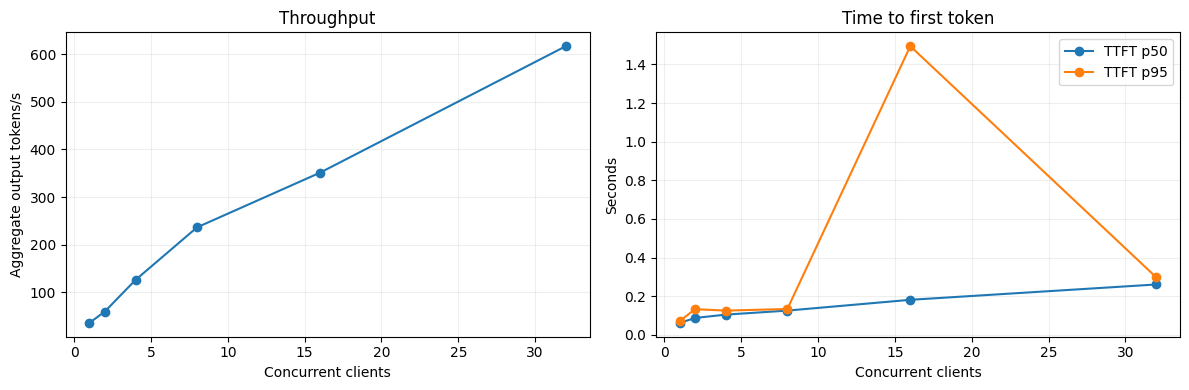

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(load_bench["concurrency"], load_bench["output tok/s"], marker="o")
ax[0].set(xlabel="Concurrent clients", ylabel="Aggregate output tokens/s", title="Throughput")
ax[1].plot(load_bench["concurrency"], load_bench["TTFT p50, s"], marker="o", label="TTFT p50")
ax[1].plot(load_bench["concurrency"], load_bench["TTFT p95, s"], marker="o", label="TTFT p95")
ax[1].set(xlabel="Concurrent clients", ylabel="Seconds", title="Time to first token")
for a in ax: a.grid(alpha=0.2)
ax[1].legend()
plt.tight_layout()
plt.show()


При увеличении числа одновременных запросов с 1 до 32 пропускная способность vLLM выросла с **36 до 617 токенов/с**, тогда как медианная задержка ответа увеличилась лишь с **1,34 до 2,01 секунды**.

Это объясняется более эффективным использованием GPU: совместная обработка нескольких последовательностей позволяет увеличить объём вычислений на одну загрузку весов модели из памяти.

Однако рост конкурентности сопровождается увеличением TTFT и времени генерации отдельных ответов. Таким образом, **батчирование повышает общую производительность сервера, но не обязательно ускоряет каждый отдельный запрос**.

В нашем эксперименте throughput продолжает расти даже при 32 одновременных клиентах, поэтому предел производительности пока не достигнут. Для определения максимальной пропускной способности и устойчивых хвостовых задержек потребуются более длительные нагрузочные тесты.

### `5.4. Мониторинг vLLM: что происходит внутри сервера?`

До этого мы измеряли производительность со стороны клиента. Но **vLLM также предоставляет внутренние метрики** через endpoint `/metrics`.

Они позволяют наблюдать за работой inference engine:

- **`num_requests_running`** — количество запросов, которые сейчас обрабатываются.
- **`num_requests_waiting`** — количество запросов, ожидающих выполнения.
- **`kv_cache_usage_perc`** — доля используемой памяти KV-cache.

По этим метрикам можно понять, насколько загружен движок, образуется ли очередь запросов и хватает ли выделенного KV-cache.

В отличие от клиентских измерений, они показывают **состояние самого vLLM**. При этом однократный запрос к `/metrics` даёт только текущие значения счётчиков; для анализа их изменения под нагрузкой необходимо собирать метрики во времени.

In [ ]:
import urllib.request

def metric_samples(names):
    """Выводит выбранные внутренние метрики vLLM."""

    # vLLM экспортирует метрики в формате Prometheus через /metrics.
    with urllib.request.urlopen(f"{BASE_URL}/metrics", timeout=6) as resp:
        lines = resp.read().decode("utf-8").splitlines()

    for line in lines:
        # Пропускаем описания метрик (# HELP, # TYPE).
        if line.startswith("#"):
            continue

        if any(line.startswith(f"vllm:{name}") for name in names):
            print(line)


metric_samples([
    "num_requests_running",
    "num_requests_waiting",
    "kv_cache_usage_perc",
])

vllm:num_requests_running{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct"} 0.0
vllm:num_requests_waiting{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct"} 0.0
vllm:num_requests_waiting_by_reason{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct",reason="capacity"} 0.0
vllm:num_requests_waiting_by_reason{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct",reason="deferred"} 0.0
vllm:kv_cache_usage_perc{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct"} 0.0


## `6. Prefix caching: переиспользование KV-cache`

Предположим, несколько пользователей обращаются к LLM с одной системной инструкцией или общим документом. При обычной обработке модель будет заново выполнять **prefill** для этого текста при каждом запросе.

**Automatic Prefix Caching (APC)** позволяет избежать повторных вычислений: vLLM сохраняет KV-cache общих префиксов и переиспользует его для последующих запросов.

Кеширование работает на уровне токенов: совпадать должен именно **начальный фрагмент последовательности**, а не просто смысл текста. В vLLM кешируемые KV-блоки идентифицируются с помощью хешей, учитывающих содержимое блоков и предшествующий контекст.

Таким образом, prefix caching может сократить время prefill и **TTFT**, особенно при длинных общих промптах. Однако он не ускоряет непосредственно генерацию новых токенов.


![Повторное использование идентичного KV-префикса и хешированных блоков в vLLM — техническая визуализация](https://pbs.twimg.com/media/HQysThObwAA-7pj.jpg)

*Повторное использование идентичного KV-префикса – [источник](https://x.com/_avichawla/article/2093265776266637739).*

### `6.1. Измеряем эффект prefix caching`

Сравним два режима vLLM: **с включённым и отключённым prefix caching**.

Для этого подготовим восемь запросов с общим префиксом длиной около 900 токенов. Перед каждым экспериментом заново запустим сервер, чтобы результаты не зависели от кеша предыдущего запуска.

В обоих режимах используем одинаковые запросы и прогрев. Разница в том, что с включённым кешированием vLLM может повторно использовать вычисленные KV-блоки вместо повторного выполнения prefill.

Сравним **TTFT** и проверим статистику попаданий в кеш (*cache hit rate*) через `/metrics`. Это позволит оценить, насколько переиспользование общего контекста ускоряет получение первого токена.

In [ ]:
# Создаём длинный общий префикс (~900 токенов).
# Первые токены всех запросов совпадают, поэтому их KV-cache можно переиспользовать.
common_prefix = (
    "Reference notes about efficient transformer inference: prefill computes keys and values "
    "for all prompt tokens, decode generates one token at a time, scheduler batches requests, "
    "and KV cache stores activations between decode steps. "
) * 22

prefix_questions = [
    common_prefix + f"\nQuestion {i}: Explain one engineering trade-off in LLM serving."
    for i in range(8)
]


def count_chat_tokens(prompt):
    """Подсчитывает длину промпта после применения chat template."""

    encoded = llm_tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
    )

    ids = encoded["input_ids"]

    if hasattr(ids, "tolist"):
        ids = ids.tolist()
    if ids and isinstance(ids[0], list):
        ids = ids[0]

    return len(ids)


# Убеждаемся, что общий контекст достаточно длинный,
# но не превышает установленное ограничение max_model_len=2048.
input_lengths = [count_chat_tokens(p) for p in prefix_questions]

print("Prompt lengths:", min(input_lengths), max(input_lengths))

assert min(input_lengths) >= 256
assert max(input_lengths) + 24 < 2048


def prefix_metric_lines():
    """Получает серверные метрики попаданий в prefix cache."""

    try:
        with urllib.request.urlopen(f"{BASE_URL}/metrics", timeout=5) as resp:
            payload = resp.read().decode("utf-8")

        # Оставляем только метрики prefix caching.
        return [
            line for line in payload.splitlines()
            if not line.startswith("#")
            and ("prefix_cache" in line or "prefix_caching" in line)
        ][:8]

    except Exception:
        return []


async def prefix_trial(cache_enabled):
    """Запускает независимый эксперимент с выбранным режимом кеширования."""

    global async_client

    # Полностью перезапускаем движок, чтобы очистить предыдущий KV-cache.
    stop_vllm_server()
    start_vllm_server(enable_prefix_caching=cache_enabled)

    # Создаём HTTP-клиент для нового экземпляра сервера.
    await async_client.close()

    async_client = AsyncOpenAI(
        base_url=f"{BASE_URL}/v1",
        api_key="EMPTY",
        timeout=120.0,
        max_retries=0,
    )

    # Технический прогрев модели.
    await request_once(
        "Give one short definition of latency.",
        max_tokens=12,
    )

    # Предварительно обрабатываем общий префикс.
    # При cache=ON его полные KV-блоки могут использоваться следующими запросами.
    await request_once(
        common_prefix + "\nWarm-up question: summarize the notes.",
        max_tokens=16,
    )

    # Последовательно отправляем восемь запросов с одинаковым префиксом.
    # concurrency=1 исключает перекрытие генераций между запросами.
    results, wall_s = await run_load_test(
        prefix_questions,
        concurrency=1,
        max_tokens=16,
    )

    # Получаем статистику переиспользования KV-блоков со стороны vLLM.
    metrics = prefix_metric_lines()

    def read_counter(kind):
        match = next(
            (
                line for line in metrics
                if line.startswith(f"vllm:prefix_cache_{kind}_total")
            ),
            None,
        )
        return float(match.split()[-1]) if match else float("nan")

    queries = read_counter("queries")
    hits = read_counter("hits")

    # Сохраняем клиентские задержки и серверную статистику кеширования.
    return {
        "prefix cache": "ON" if cache_enabled else "OFF",
        "TTFT median, s": float(np.nanmedian([r["ttft_s"] for r in results])),
        "TTFT mean, s": float(np.nanmean([r["ttft_s"] for r in results])),
        "E2E median, s": float(np.median([r["e2e_s"] for r in results])),
        "wall, s": float(wall_s),
        "cached tokens / queried tokens": (
            hits / queries if queries > 0 else float("nan")
        ),
    }


# Проводим A/B-тест: сначала без кеширования, затем с кешированием.
prefix_rows = []

for enabled in (False, True):
    print("Prefix caching:", "ON" if enabled else "OFF")
    prefix_rows.append(await prefix_trial(enabled))

prefix_bench = pd.DataFrame(prefix_rows)
display(prefix_bench.round(3))

# Сохраняем результаты для последующего сравнения.
prefix_bench.to_csv("vllm_prefix_cache_ab.csv", index=False)

# Измеряем относительное снижение времени до первого токена.
ttft_off = prefix_bench.loc[
    prefix_bench["prefix cache"] == "OFF", "TTFT mean, s"
].iloc[0]

ttft_on = prefix_bench.loc[
    prefix_bench["prefix cache"] == "ON", "TTFT mean, s"
].iloc[0]

print(f"TTFT reduction: {(ttft_off - ttft_on) / ttft_off * 100:.1f}%")

Actual prompt lengths (tokens): 902 902
Testing prefix cache: OFF
Prefix caching: OFF -> --no-enable-prefix-caching
Launching: /usr/bin/python3 -m vllm.entrypoints.cli.main serve Qwen/Qwen2.5-0.5B-Instruct --host 127.0.0.1 --port 8765 --dtype float16 --max-model-len 2048 --gpu-memory-utilization 0.75 --max-num-seqs 32 --enforce-eager --no-enable-prefix-caching
Waiting for vLLM... 30s
vLLM is ready after ~60s; prefix cache = False
Prefix cache counters: ['vllm:prefix_cache_queries_total{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct"} 0.0', 'vllm:prefix_cache_hits_total{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct"} 0.0', 'vllm:external_prefix_cache_queries_total{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct"} 0.0', 'vllm:external_prefix_cache_hits_total{engine="0",model_name="Qwen/Qwen2.5-0.5B-Instruct"} 0.0']
Testing prefix cache: ON
Prefix caching: ON -> --enable-prefix-caching
Launching: /usr/bin/python3 -m vllm.entrypoints.cli.main serve Qwen/Qwen2.5-0.5B-Instruct --hos

,prefix cache,"TTFT median, s","TTFT mean, s","E2E median, s","wall, s",cached tokens / queried tokens
0,OFF,0.104,0.105,0.504,4.050,NaN
1,ON,0.069,0.072,0.471,3.753,0.866


Observed mean TTFT difference: 31.3% (single run; not a robust speedup estimate)


С включённым prefix caching средний TTFT снизился со **105 до 72 мс (на 31,3%)**, а полное время обработки восьми запросов — с 4,05 до 3,75 секунды.

При этом **86,6% запрошенных токенов были найдены в KV-cache**. Это подтверждает, что vLLM действительно переиспользует общий префикс и сокращает повторные вычисления на стадии prefill.

Выигрыш заметен прежде всего в TTFT, поскольку prefix caching не ускоряет саму генерацию новых токенов. Результаты получены для восьми запросов с длинным общим префиксом.

### 6.2 Работа с "документом"

Упражнение: попробуйте запустить систему на подобии документа, который не меняется и используется в нескольких вопросах, связанных с ним. Поможет ли префиксное кэширование в таком случае? Почему?

In [ ]:

# Один технический документ, к которому задаём несколько независимых вопросов.
# Все запросы имеют одинаковый длинный префикс, но разные окончания.

document = """
Technical Note: Architecture and Performance of LLM Inference Systems

Autoregressive language models generate text one token at a time. At each
generation step, the model receives the previously generated sequence and
predicts a probability distribution over the next token. Although transformer
models can process an entire prompt in parallel, generation remains sequential
because every new token depends on the preceding tokens.

Inference is usually divided into two phases: prefill and decode. During
prefill, the model processes all input tokens and computes the key and value
representations required by attention. Large prompts involve substantial
matrix multiplications, making prefill relatively compute-intensive. During
decode, the model generates new tokens incrementally, reusing previously
computed attention states. Decode often becomes limited by memory bandwidth,
especially when the batch size is small.

The key-value cache, or KV-cache, avoids recomputing attention states for
previous tokens at every decoding step. For each transformer layer, the
system stores key and value tensors corresponding to the processed tokens.
The memory occupied by these tensors increases approximately linearly with
sequence length and the number of active requests. Consequently, KV-cache
capacity can become a major limitation when serving models with long
contexts or large numbers of concurrent users.

Traditional static batching combines several requests into a fixed batch.
However, requests may have different prompt lengths and may generate
different numbers of output tokens. If completed requests cannot leave
the batch immediately, GPU resources are wasted. Continuous batching
addresses this problem by allowing the inference engine to update the
composition of the batch between generation steps. Completed requests
are removed, while newly arriving requests can be admitted according
to the scheduler's available resources.

The scheduler determines which requests should execute on the next GPU
step. Its decisions depend on the available token budget, KV-cache
capacity, and the current state of active requests. Some systems also
support chunked prefill, which divides the processing of long prompts
into smaller segments. This allows prefill and decode computations
to be interleaved, potentially improving the balance between throughput
and latency under mixed workloads.

Efficient memory management is essential for continuous batching.
PagedAttention organizes the KV-cache into fixed-size blocks rather
than requiring one large contiguous allocation for each sequence.
Logical blocks are mapped to physical blocks in GPU memory. This
reduces memory fragmentation and allows the system to allocate
additional capacity as a sequence grows. Block-based management
also makes it possible to share existing KV-cache blocks between
requests when their token prefixes are identical.

Automatic prefix caching takes advantage of repeated contexts.
Consider an application where every user request includes the same
long system instruction or reference document. Without caching,
the model computes attention states for this shared prefix again
for every request. With prefix caching, previously computed KV
blocks can be reused by subsequent requests. Only the new portion
of each prompt needs additional prefill computation, provided that
the cached blocks remain available and the token prefixes match.

Prefix caching primarily reduces redundant prefill computation.
It does not eliminate the need to generate output tokens
autoregressively. Its effectiveness therefore depends on the
fraction of each prompt that can be reused, the cache hit rate,
and the relationship between prefill and decode costs.

Performance evaluation must distinguish latency from throughput.
Time to First Token, or TTFT, measures how long a request waits
before receiving its first generated token. Time per Output Token,
or TPOT, characterizes the speed of subsequent generation.
Throughput measures the amount of work completed per second,
often expressed as generated tokens per second or requests per
second. Increasing concurrency may improve throughput while
also increasing the latency experienced by individual users.

Inference frameworks emphasize different engineering choices.
ONNX Runtime focuses on executing optimized computational graphs
across different hardware backends. vLLM and SGLang specialize
in efficient autoregressive generation and request scheduling.
TensorRT-LLM provides NVIDIA-focused optimizations for LLM inference.
llama.cpp emphasizes portability and efficient execution on a
variety of devices, including CPUs and Apple Silicon.

No single inference engine is optimal for every workload.
The appropriate choice depends on model architecture, hardware,
context length, request concurrency, latency requirements,
and operational constraints. Reliable comparisons require
consistent workloads, clearly defined metrics, and careful
measurement of both average and tail latency.
""".strip()

# Вопросы специально затрагивают разные разделы одного документа.
questions = [
    "What is the difference between prefill and decode?",
    "Why does KV-cache memory grow with sequence length?",
    "How does continuous batching improve GPU utilization?",
    "What is the role of the scheduler in an inference engine?",
    "How does PagedAttention reduce memory fragmentation?",
    "Why can prefix caching reduce TTFT?",
    "What is the trade-off between throughput and latency?",
    "How do vLLM, ONNX Runtime, and llama.cpp differ?",
]

# Документ должен находиться В НАЧАЛЕ каждого запроса.
# Именно такой общий token prefix сможет повторно использовать vLLM.
common_prefix = (
    "Answer questions using the following technical document.\n\n"
    f"{document}\n\n"
)

prefix_questions = [
    common_prefix + f"Question: {question}\nAnswer concisely."
    for question in questions
]

# Проверяем реальную длину после токенизации с chat template.
input_lengths = [count_chat_tokens(p) for p in prefix_questions]

print("Document words:", len(document.split()))
print("Prompt tokens:", min(input_lengths), max(input_lengths))
print("Number of questions:", len(prefix_questions))

assert min(input_lengths) >= 256
assert max(input_lengths) + 24 < 2048


In [ ]:
# Повторяем A/B-тест на новом документе и восьми вопросах.
# prefix_trial() использует актуальные переменные common_prefix и prefix_questions.
# Перед каждым режимом сервер перезапускается, чтобы очистить предыдущий KV-cache.

prefix_rows = []

for enabled in (False, True):
    print("Prefix caching:", "ON" if enabled else "OFF")
    prefix_rows.append(await prefix_trial(enabled))

# Сравниваем время до первого токена и статистику кеширования.
prefix_bench_document = pd.DataFrame(prefix_rows)
display(prefix_bench_document.round(3))

# Вычисляем относительное изменение среднего TTFT.
ttft_off = prefix_bench_document.loc[
    prefix_bench_document["prefix cache"] == "OFF", "TTFT mean, s"
].iloc[0]

ttft_on = prefix_bench_document.loc[
    prefix_bench_document["prefix cache"] == "ON", "TTFT mean, s"
].iloc[0]

print(f"TTFT reduction: {(ttft_off - ttft_on) / ttft_off * 100:.1f}%")

## `7. llama.cpp: локальный инференс на Apple Silicon`

До этого мы запускали vLLM на NVIDIA GPU в Colab. Теперь посмотрим на другой сценарий — **запуск языковой модели локально на Mac**.

Для этого воспользуемся **llama.cpp** — inference-фреймворком на C/C++, который поддерживает различные аппаратные платформы, квантованные модели в формате GGUF и ускорение через Metal на Apple Silicon.

Возьмём ту же **Qwen2.5-0.5B-Instruct**, но в двух вариантах квантования: `Q4_K_M` (4-битное семейство) и `Q8_0` (8-битное). Сравним размер моделей, потребление памяти и производительность на GPU и CPU.

С помощью `llama-bench` отдельно измерим скорость обработки входного контекста (**prefill**) и генерации новых токенов (**decode**). Это позволит увидеть, как квантование и выбор аппаратного ускорителя влияют на разные этапы инференса.

Все зависимости, исходный код llama.cpp и веса моделей разместим в отдельной папке проекта, а Python-библиотеки установим в виртуальное окружение `.venv`.

### `7.1. Подготовка окружения`

Для локального инференса создадим отдельную папку проекта и виртуальное Python-окружение. В ней будут храниться исходники llama.cpp, скомпилированные бинарники и веса моделей.

Выполняем в **терминале macOS**:

```bash
# Проверяем архитектуру Mac, версию macOS и наличие инструментов компиляции.
uname -m
sw_vers -productVersion
xcode-select -p

# Создаём папку проекта и каталоги для моделей и кеша.
mkdir -p "$HOME/projects/efficient-inference-seminar"
cd "$HOME/projects/efficient-inference-seminar"
mkdir -p models .cache/pip .cache/huggingface

# Создаём и активируем виртуальное Python-окружение.
python3 -m venv .venv
source .venv/bin/activate

# Храним кеши зависимостей и моделей внутри проекта.
export PIP_CACHE_DIR="$PWD/.cache/pip"
export HF_HOME="$PWD/.cache/huggingface"

# Устанавливаем инструменты сборки и библиотеки для загрузки моделей и HTTP-клиента.
python -m pip install --upgrade pip
python -m pip install cmake ninja huggingface_hub openai

# Проверяем пути к инструментам из виртуального окружения.
which python
which cmake
which ninja
```

Далее соберём **llama.cpp с поддержкой Metal** непосредственно в этой папке. Python-зависимости останутся изолированными в `.venv`, а C++-бинарники будут храниться отдельно внутри проекта.

### `7.2. Сборка llama.cpp с поддержкой Metal`

Теперь соберём **llama.cpp из исходного кода**. Включим backend Metal, чтобы выполнять вычисления на GPU Apple Silicon.

Соберём три программы: `llama-cli` для генерации текста, `llama-server` для запуска HTTP-сервера и `llama-bench` для измерения производительности.

```bash
# Возвращаемся в каталог проекта и активируем окружение.
cd "$HOME/projects/efficient-inference-seminar"
source .venv/bin/activate

# Загружаем исходный код llama.cpp.
git clone --depth 1 https://github.com/ggml-org/llama.cpp.git llama.cpp

# Конфигурируем сборку:
# Release — оптимизированная сборка;
# GGML_METAL=ON — ускорение вычислений через Metal;
# LLAMA_CURL=OFF — сборка без зависимости от libcurl.
cmake -S llama.cpp -B build -G Ninja \
  -DCMAKE_BUILD_TYPE=Release \
  -DGGML_METAL=ON \
  -DLLAMA_CURL=OFF

# Собираем CLI, HTTP-сервер и инструмент для benchmark.
cmake --build build --parallel 4 \
  --target llama-cli llama-server llama-bench

# Проверяем наличие исполняемых файлов.
ls -lh build/bin/llama-cli build/bin/llama-server build/bin/llama-bench

# Фиксируем версию исходного кода для воспроизводимости измерений.
git -C llama.cpp rev-parse --short HEAD
```

Все бинарники останутся в каталоге проекта. В следующем эксперименте загрузим квантованные веса Qwen и сравним **скорость обработки промпта и генерации токенов** при выполнении на Metal и CPU.

### `7.3. GGUF: сравниваем разные уровни квантования`

**GGUF** — формат хранения языковых моделей, содержащий веса, параметры архитектуры и информацию о токенизаторе.

Загрузим два варианта **Qwen2.5-0.5B-Instruct**:

- **Q4_K_M** — более компактное представление весов с преимущественно 4-битным квантованием.
- **Q8_0** — 8-битное квантование, требующее больше памяти, но обычно сохраняющее более высокую численную точность.

Квантование уменьшает объём данных, которые необходимо читать из памяти, однако добавляет расходы на деквантование. Поэтому **меньший размер модели не обязательно означает более быструю генерацию**.

```bash
# Переходим в проект и активируем Python-окружение.
cd "$HOME/projects/efficient-inference-seminar"
source .venv/bin/activate
export HF_HOME="$PWD/.cache/huggingface"

# Загружаем два варианта квантования одной модели.
python - <<'PY'
from huggingface_hub import hf_hub_download
from pathlib import Path

repo_id = "Qwen/Qwen2.5-0.5B-Instruct-GGUF"

for name in (
    "qwen2.5-0.5b-instruct-q4_k_m.gguf",
    "qwen2.5-0.5b-instruct-q8_0.gguf",
):
    path = Path(hf_hub_download(
        repo_id=repo_id,
        filename=name,
        local_dir="models",
    ))

    print(f"{path.name}: {path.stat().st_size / 2**20:.1f} MiB")
PY

# Сравниваем размеры файлов.
ls -lh models/*.gguf

# Запускаем Q4_K_M с ускорением через Metal.
# --n-gpu-layers 99 разрешает перенести на GPU до 99 слоёв.
./build/bin/llama-cli \
  -m models/qwen2.5-0.5b-instruct-q4_k_m.gguf \
  -p "Explain attention in transformers." \
  -n 64 \
  --n-gpu-layers 99
```

В выводе `llama-cli` посмотрим, сколько слоёв фактически перенесено на GPU, и сравним время обработки промпта (*prompt evaluation*) со временем генерации (*token evaluation*).

Далее измерим эти этапы отдельно с помощью `llama-bench` для обоих вариантов квантования.

### `7.4. Запуск локального inference-сервера`

Как и vLLM, **llama.cpp поддерживает OpenAI-совместимый API**. Это позволяет обращаться к локальной модели через тот же Python-клиент, который мы использовали для vLLM.

Запустим HTTP-сервер с моделью Q4_K_M на Mac, а затем отправим запрос через `chat.completions`.

**Терминал №1 — запускаем сервер:**

```bash
# Переходим в каталог проекта.
cd "$HOME/projects/efficient-inference-seminar"
source .venv/bin/activate

# Загружаем GGUF-модель и запускаем HTTP-сервер с ускорением через Metal.
# Сервер доступен только локально, на порту 8080.
./build/bin/llama-server \
  --model models/qwen2.5-0.5b-instruct-q4_k_m.gguf \
  --host 127.0.0.1 \
  --port 8080 \
  --ctx-size 2048 \
  --n-gpu-layers 99
```

**Терминал №2 — отправляем запрос:**

```bash
# Активируем окружение в отдельном терминале.
cd "$HOME/projects/efficient-inference-seminar"
source .venv/bin/activate

# Проверяем доступность сервера и список загруженных моделей.
curl -fsS http://127.0.0.1:8080/health
curl -fsS http://127.0.0.1:8080/v1/models

# Создаём Python-клиент для обращения к llama.cpp.
cat > local_client.py <<'CLIENT_PY'
from openai import OpenAI
import time

# Используем тот же клиент OpenAI, что и в эксперименте с vLLM.
# Меняется только адрес inference-сервера.
client = OpenAI(
    base_url="http://127.0.0.1:8080/v1",
    api_key="EMPTY",
    timeout=120,
)

model_id = client.models.list().data[0].id

# Измеряем полное время обработки запроса на стороне клиента.
start = time.perf_counter()

response = client.chat.completions.create(
    model=model_id,
    messages=[
        {
            "role": "user",
            "content": "Explain prefill and decode briefly.",
        }
    ],
    temperature=0,
    max_tokens=96,
)

print("Model:", model_id)
print("Response:", response.choices[0].message.content)
print("E2E latency:", round(time.perf_counter() - start, 3), "s")
CLIENT_PY

# Выполняем запрос к локальной модели.
python local_client.py
```

Обрати внимание: **клиентский код практически не изменился по сравнению с vLLM**. Мы лишь указали другой адрес сервера.

При этом за одинаковым API стоят разные реализации инференса: llama.cpp использует GGUF и Metal на Apple Silicon, тогда как ранее vLLM выполнял модель в FP16 на NVIDIA GPU.

Таким образом, общий API упрощает интеграцию моделей в приложения, но не означает одинаковую производительность разных inference engines.

### `7.5. Сравниваем квантование и вычислительные backend`

Теперь измерим производительность **одной модели в разных конфигурациях**:

- **Q4 + Metal** — 4-битное квантование на GPU.
- **Q8 + Metal** — 8-битное квантование на GPU.
- **Q4 + CPU** — та же 4-битная модель, но без GPU.

Для измерений используем `llama-bench`. Он отдельно оценивает скорость обработки входного контекста (**prefill**) и генерации новых токенов (**decode**).

Во всех трёх случаях зададим 512 входных токенов, 128 генерируемых токенов и три повтора.

```bash
cd "$HOME/projects/efficient-inference-seminar"
source .venv/bin/activate

# Q4 + Metal: компактные веса, вычисления на GPU.
./build/bin/llama-bench \
  -m models/qwen2.5-0.5b-instruct-q4_k_m.gguf \
  -p 512 -n 128 -ngl 99 -r 3

# Q8 + Metal: более точное представление весов, тот же GPU.
./build/bin/llama-bench \
  -m models/qwen2.5-0.5b-instruct-q8_0.gguf \
  -p 512 -n 128 -ngl 99 -r 3

# Q4 + CPU: те же веса Q4, но без переноса слоёв на GPU.
./build/bin/llama-bench \
  -m models/qwen2.5-0.5b-instruct-q4_k_m.gguf \
  -p 512 -n 128 -ngl 0 -r 3
```

В результатах нас интересуют две строки:

- **`pp512`** — скорость обработки промпта из 512 токенов.
- **`tg128`** — скорость последовательной генерации 128 токенов.

Обе скорости измеряются в токенах в секунду, но относятся к разным этапам инференса.

Сравнение **Q4 и Q8 на Metal** покажет влияние квантования. Меньшие веса требуют меньше памяти и передаваемых данных, однако расходы на деквантование и особенности GPU kernels тоже влияют на скорость.

Сравнение **Q4 на Metal и CPU** позволит оценить преимущество GPU-ускорения на одном устройстве.

Не стоит напрямую сравнивать полученные значения с результатами vLLM на T4: там отличались аппаратная платформа, точность весов и сам inference engine.

## `8. SGLang и TensorRT-LLM: альтернативы vLLM`

### `8.1. SGLang и RadixAttention`

**SGLang** — ещё один движок для эффективного инференса LLM. Одна из его ключевых идей — **RadixAttention**, механизм переиспользования KV-cache между запросами.

Вместо независимого хранения общих префиксов SGLang организует их в виде **radix tree** — дерева, в котором запросы с одинаковым началом используют общие ветви. Это особенно полезно, когда множество запросов обращаются к одному документу, имеют длинную системную инструкцию или разделяют историю диалога.

При этом prefix caching есть и в vLLM — мы уже проверили его в предыдущем эксперименте. **Главное отличие RadixAttention — способ организации и управления кешированными префиксами**, а не сама возможность переиспользовать KV-cache.

![RadixAttention: prefix matching, reuse и eviction — рисунок команды SGLang](https://openlm.ai/assets/blog/sglang/radix_attn.jpg)

*RadixAttention: prefix matching, reuse и eviction — рисунок команды SGLang — [источник](https://openlm.ai/sglang/).*

### `8.2. TensorRT-LLM: оптимизация под NVIDIA GPU`

**TensorRT-LLM** — движок для инференса языковых моделей, оптимизированный под NVIDIA GPU. Он использует специализированные CUDA-операции, объединение вычислений (*kernel fusion*), квантование и другие оптимизации для ускорения генерации.

В отличие от **TensorRT Execution Provider** в ONNX Runtime, который выполняет поддерживаемые части ONNX-графа, TensorRT-LLM — полноценный LLM inference engine со своим планировщиком запросов и управлением KV-cache.

Одна из важных оптимизаций — **chunked prefill**. Вместо обработки длинного промпта целиком его разбивают на части. Это позволяет планировщику совмещать prefill новых запросов с decode уже активных, чтобы длинный входной контекст не задерживал генерацию для остальных пользователей.

Таким образом, TensorRT-LLM решает те же задачи эффективного LLM serving, что и vLLM и SGLang, но делает особый акцент на оптимизации вычислений под оборудование NVIDIA.

![Chunked prefill в TensorRT-LLM: задержка decode до и после интерливинга — NVIDIA](https://pbs.twimg.com/media/GcdEyeWW0AAnxt_.png)

*Chunked prefill в TensorRT-LLM: задержка decode до и после интерливинга — NVIDIA — [источник](https://developer.nvidia.com/blog/streamlining-ai-inference-performance-and-deployment-with-nvidia-tensorrt-llm-chunked-prefill/).*

## `Сравнение inference frameworks`

Эффективность инференса зависит не только от модели, но и от того, **как организованы вычисления, память и обработка запросов**.

| Инструмент | Основная идея | Когда использовать |
|---|---|---|
| **ONNX Runtime** | Оптимизация вычислительного графа и выполнение через Execution Providers | Инференс различных моделей на CPU, GPU и NPU |
| **vLLM** | Continuous batching и эффективное управление KV-cache | Обслуживание большого количества одновременных LLM-запросов |
| **SGLang** | Переиспользование общих префиксов и управление генерацией | Агентные сценарии, повторяющиеся контексты, structured generation |
| **TensorRT-LLM** | Специализированные kernels и оптимизации под NVIDIA GPU | Высокопроизводительный LLM serving на NVIDIA |
| **llama.cpp** | Легковесный runtime и поддержка квантованных моделей | Локальный инференс на CPU, Apple Silicon и потребительских GPU |

**Какой framework быстрее?** Универсального ответа нет. Всё зависит от модели, оборудования, точности вычислений и характера нагрузки: длины промптов, количества одновременных запросов и соотношения prefill/decode.

Поэтому корректно сравнивать inference engines можно только **при сопоставимых условиях**, учитывая и throughput, и latency.

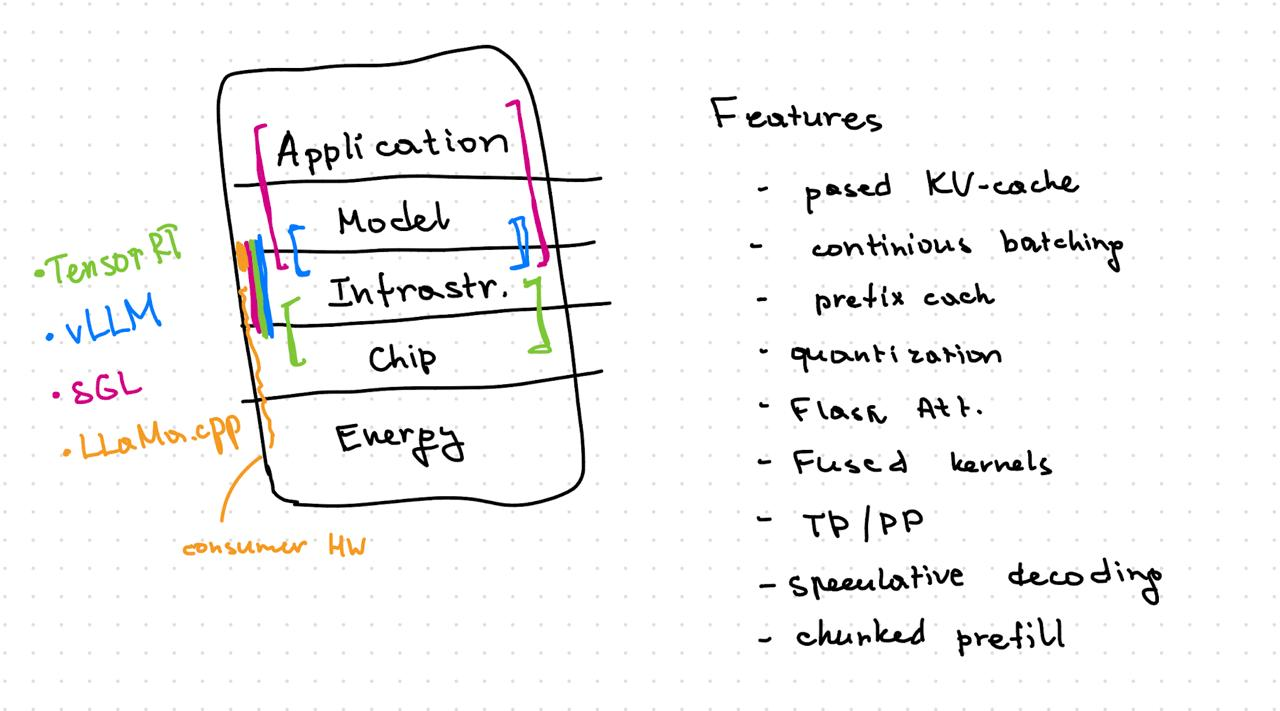

Разные inference engines оптимизируют разные части этой системы. Например, vLLM делает акцент на планировании запросов и управлении KV-cache, SGLang — на переиспользовании общих префиксов, а llama.cpp — на эффективном запуске квантованных моделей, в том числе на потребительском оборудовании.

При этом многие оптимизации — continuous batching, prefix caching, fused kernels, quantization — поддерживаются сразу несколькими движками.

Главная идея: эффективность инференса зависит не только от архитектуры модели, но и от того, как организованы вычисления, память и обработка запросов на конкретном оборудовании.

## `10. Источники`

**ONNX / ORT:** [PyTorch ONNX exporter](https://docs.pytorch.org/docs/stable/onnx.html), [High-level design](https://onnxruntime.ai/docs/reference/high-level-design.html), [Execution Providers](https://onnxruntime.ai/docs/execution-providers/), [Graph optimizations](https://onnxruntime.ai/docs/performance/model-optimizations/graph-optimizations.html).

**vLLM:** [Inside vLLM — Aleksa Gordić, 2025](https://vllm.ai/blog/2025-09-05-anatomy-of-vllm), [PagedAttention — Kwon et al., 2023](https://arxiv.org/abs/2309.06180), [Architecture overview](https://docs.vllm.ai/en/v0.15.1/design/arch_overview/), [Server metrics](https://docs.vllm.ai/en/latest/usage/metrics/), [Automatic prefix caching](https://docs.vllm.ai/en/latest/features/automatic_prefix_caching/).

**Scheduling:** [Hugging Face / TNG — Prefill and Decode for Concurrent Requests](https://huggingface.co/blog/tngtech/llm-performance-prefill-decode-concurrent-requests).

**SGLang:** [RadixAttention — оригинальный материал проекта](https://openlm.ai/sglang/), [Documentation](https://docs.sglang.ai/).

**TensorRT-LLM:** [NVIDIA TensorRT-LLM](https://nvidia.github.io/TensorRT-LLM/), [NVIDIA: Chunked Prefill](https://developer.nvidia.com/blog/streamlining-ai-inference-performance-and-deployment-with-nvidia-tensorrt-llm-chunked-prefill/).

**llama.cpp:** [Репозиторий и сборка](https://github.com/ggml-org/llama.cpp), [HTTP server](https://github.com/ggml-org/llama.cpp/tree/master/tools/server), [Qwen GGUF](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct-GGUF/tree/main).


In [ ]:
# Освобождаем GPU
stop_vllm_server()
print("vLLM server stopped")

vLLM server stopped
